# 01 · Data exploration
**Goal:** understand every table *before* joining anything — shape, types, nulls, duplicates, key uniqueness, relationships and time coverage.

Source: [Olist Brazilian E-Commerce Public Dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (9 CSVs, ~100k orders, 2016–2018).

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
import olist
olist.setup_plots()
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 40
BRL = mtick.FuncFormatter(lambda x, p: f"R${x/1e6:.1f}M" if abs(x) >= 1e6 else f"R${x/1e3:.0f}k")

In [2]:
t = olist.load_raw()
summary = pd.DataFrame({
    "rows": {k: len(v) for k, v in t.items()},
    "columns": {k: v.shape[1] for k, v in t.items()},
    "null_cells": {k: int(v.isna().sum().sum()) for k, v in t.items()},
    "duplicate_rows": {k: int(v.duplicated().sum()) for k, v in t.items()},
})
summary

,rows,columns,null_cells,duplicate_rows
orders,99441,8,4908,0
items,112650,7,0,0
customers,99441,5,0,0
products,32951,9,2448,0
payments,103886,5,0,0
reviews,99224,7,145903,0
sellers,3095,4,0,0
translation,71,2,0,0
geolocation,1000163,5,0,261831


**Reading the table:** `geolocation` has ~1M rows and a large number of exact duplicate rows (several coordinates per zip prefix) — it is only useful aggregated to one row per zip prefix, and is not needed for any of the core questions. Every other table has zero fully-duplicated rows.

## Column-level inspection

In [3]:
for name in ["orders", "items", "customers", "products", "payments", "reviews", "sellers"]:
    df = t[name]
    print(f"\n=== {name}  {df.shape} ===")
    display(pd.DataFrame({"dtype": df.dtypes.astype(str), "nulls": df.isna().sum(), "null_%": 100*df.isna().mean(), "n_unique": df.nunique()}))


=== orders  (99441, 8) ===


,dtype,nulls,null_%,n_unique
order_id,str,0,0.00,99441
customer_id,str,0,0.00,99441
order_status,str,0,0.00,8
order_purchase_timestamp,str,0,0.00,98875
order_approved_at,str,160,0.16,90733
order_delivered_carrier_date,str,1783,1.79,81018
order_delivered_customer_date,str,2965,2.98,95664
order_estimated_delivery_date,str,0,0.00,459



=== items  (112650, 7) ===


,dtype,nulls,null_%,n_unique
order_id,str,0,0.00,98666
order_item_id,int64,0,0.00,21
product_id,str,0,0.00,32951
seller_id,str,0,0.00,3095
shipping_limit_date,str,0,0.00,93318
price,float64,0,0.00,5968
freight_value,float64,0,0.00,6999



=== customers  (99441, 5) ===


,dtype,nulls,null_%,n_unique
customer_id,str,0,0.00,99441
customer_unique_id,str,0,0.00,96096
customer_zip_code_prefix,int64,0,0.00,14994
customer_city,str,0,0.00,4119
customer_state,str,0,0.00,27


... (4 outputs left out)


=== reviews  (99224, 7) ===


,dtype,nulls,null_%,n_unique
review_id,str,0,0.00,98410
order_id,str,0,0.00,98673
review_score,int64,0,0.00,5
review_comment_title,str,87656,88.34,4527
review_comment_message,str,58247,58.70,36159
review_creation_date,str,0,0.00,636
review_answer_timestamp,str,0,0.00,98248



=== sellers  (3095, 4) ===


,dtype,nulls,null_%,n_unique
seller_id,str,0,0.00,3095
seller_zip_code_prefix,int64,0,0.00,2246
seller_city,str,0,0.00,611
seller_state,str,0,0.00,23


## Key uniqueness (is each ID really the grain I think it is?)

In [4]:
checks = {
    "orders.order_id": t["orders"]["order_id"],
    "customers.customer_id": t["customers"]["customer_id"],
    "customers.customer_unique_id": t["customers"]["customer_unique_id"],
    "products.product_id": t["products"]["product_id"],
    "sellers.seller_id": t["sellers"]["seller_id"],
    "reviews.review_id": t["reviews"]["review_id"],
    "reviews.order_id": t["reviews"]["order_id"],
}
pd.DataFrame({k: {"rows": len(s), "unique": s.nunique(), "is_unique": s.is_unique} for k, s in checks.items()}).T

,rows,unique,is_unique
orders.order_id,99441,99441,True
customers.customer_id,99441,99441,True
customers.customer_unique_id,99441,96096,False
products.product_id,32951,32951,True
sellers.seller_id,3095,3095,True
reviews.review_id,99224,98410,False
reviews.order_id,99224,98673,False


In [5]:
# composite keys
print("order_items (order_id, order_item_id) unique:", not t["items"].duplicated(["order_id","order_item_id"]).any())
print("payments    (order_id, payment_sequential) unique:", not t["payments"].duplicated(["order_id","payment_sequential"]).any())
print("\ncustomer_id is per-ORDER; customer_unique_id is the real person:")
print(f"  {t['customers'].customer_id.nunique():,} customer_ids  ->  {t['customers'].customer_unique_id.nunique():,} unique customers")

order_items (order_id, order_item_id) unique: True
payments    (order_id, payment_sequential) unique: True

customer_id is per-ORDER; customer_unique_id is the real person:
  99,441 customer_ids  ->  96,096 unique customers


**Key takeaways**
- `orders.order_id` is unique → one row per order.
- `customer_id` is generated *per order*; repeat-purchase analysis **must** use `customer_unique_id`.
- `reviews.review_id` is **not** unique and some orders carry more than one review → reviews need de-duplication to order grain.
- `order_items` and `payments` are many-rows-per-order → aggregate before joining (otherwise revenue is inflated).

## Table relationships (referential integrity)

In [6]:
def orphan(child, ccol, parent, pcol):
    return int((~t[child][ccol].isin(t[parent][pcol])).sum())

rel = pd.DataFrame([
    ("orders.customer_id",        "customers.customer_id", orphan("orders","customer_id","customers","customer_id")),
    ("order_items.order_id",      "orders.order_id",       orphan("items","order_id","orders","order_id")),
    ("order_items.product_id",    "products.product_id",   orphan("items","product_id","products","product_id")),
    ("order_items.seller_id",     "sellers.seller_id",     orphan("items","seller_id","sellers","seller_id")),
    ("payments.order_id",         "orders.order_id",       orphan("payments","order_id","orders","order_id")),
    ("reviews.order_id",          "orders.order_id",       orphan("reviews","order_id","orders","order_id")),
], columns=["child key", "parent key", "orphan rows"])
rel

,child key,parent key,orphan rows
0,orders.customer_id,customers.customer_id,0
1,order_items.order_id,orders.order_id,0
2,order_items.product_id,products.product_id,0
3,order_items.seller_id,sellers.seller_id,0
4,payments.order_id,orders.order_id,0
5,reviews.order_id,orders.order_id,0


```
customers ──< orders >── order_items >── products ──(category)── category_translation
                │              └────< sellers
                ├──< payments
                └──< reviews          geolocation (zip prefix → lat/lng, standalone)
```
No orphans: every foreign key resolves. Joins on these keys will not silently drop rows.

## Time coverage & order status

First purchase: 2016-09-04 21:15:19 | Last purchase: 2018-10-17 17:30:18


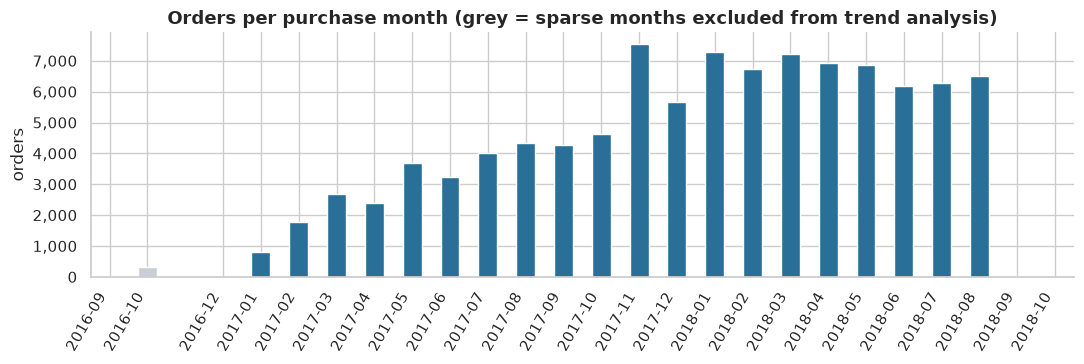

In [7]:
o = olist.clean_orders(t["orders"])
print("First purchase:", o.order_purchase_timestamp.min(), "| Last purchase:", o.order_purchase_timestamp.max())
monthly = o.groupby("purchase_month").size()
fig, ax = plt.subplots(figsize=(11, 3.8))
monthly.plot(kind="bar", ax=ax, color=np.where((monthly.index >= "2017-01") & (monthly.index <= "2018-08"), "#2a6f97", "#c9ced6"))
ax.set_title("Orders per purchase month (grey = sparse months excluded from trend analysis)")
ax.set_xlabel(""); ax.set_ylabel("orders")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
plt.xticks(rotation=60, ha="right"); plt.tight_layout()
olist.save_fig(fig, "00_orders_per_month_coverage.png")

**Decision:** 2016 (4 + 324 + 1 orders) and Sep–Oct 2018 (20 orders) are tiny, partial months — including them would create fake growth rates (e.g. +29,777% MoM). All **trend** charts use **2017-01 → 2018-08**; totals/shares use all delivered orders.

In [8]:
status = o.order_status.value_counts().to_frame("orders")
status["share_%"] = 100 * status.orders / status.orders.sum()
status

,orders,share_%
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


In [9]:
# Data-dictionary seed: what does each purchase-lifecycle timestamp look like for each status?
o.groupby("order_status")[olist.ORDER_DATE_COLS].agg(lambda s: s.notna().mean()*100).round(1)

,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
order_status,,,,,
approved,100.00,100.00,0.00,0.00,100.00
canceled,100.00,77.40,12.00,1.00,100.00
created,100.00,0.00,0.00,0.00,100.00
delivered,100.00,100.00,100.00,100.00,100.00
invoiced,100.00,100.00,0.00,0.00,100.00
processing,100.00,100.00,0.00,0.00,100.00
shipped,100.00,100.00,100.00,0.00,100.00
unavailable,100.00,100.00,0.00,0.00,100.00


Read as "% of orders in that status that have the timestamp". Delivered orders almost always have all dates; canceled/unavailable orders mostly lack delivery dates (as expected). Two anomalies (8 `delivered` rows without a delivery date; 6 `canceled` rows *with* one) are handled in notebook 02.